# 04 · An agent drives the robot

The same two tools as notebook 03, now used to move an SO-101: poses from plain English, a policy run by name,
an e-stop the agent can press but not release, and a hardware arm whose operator gate refuses the model.
Every turn is a real Claude call on Amazon Bedrock; a re-run gets different replies.

![an agent's act goes through the safety chain; a refusal comes back to the model as text](media/04/gate.svg)

In [1]:
import json
import math
import os
import sys

import numpy as np
from strands import Agent

import _nb
from strands_robots import Robot, Simulation

MEDIA = _nb.MEDIA / "04"
MEDIA.mkdir(parents=True, exist_ok=True)
print("model:", os.environ["STRANDS_MODEL_ID"])

model: global.anthropic.claude-opus-5-5


A world with the arm and a red cube on the floor in front of it (the arm reaches along -y).


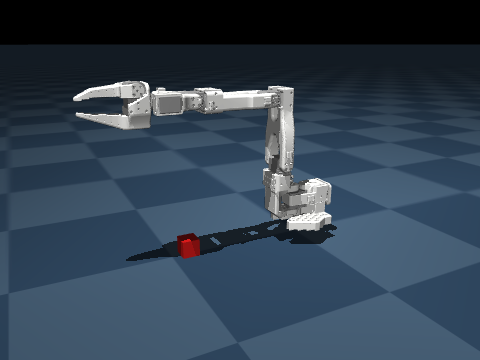

In [2]:
sim = Simulation()
arm = Robot("so101", sim=sim)
sim.add_object("red_cube", shape="box", size=(0.015, 0.015, 0.015), position=(0.0, -0.22, 0.015), color=(0.85, 0.1, 0.1, 1))
sim.camera("side", position=(0.65, -0.45, 0.35), target=(0.0, -0.12, 0.12), size=(480, 360))
_nb.show(_nb.image(sim.render("side"), width=480))

A policy is any callable from an `Observation` to joint targets. Registered on the tool as a handle, the model runs it
by name; it never types a network address or a file path.

In [3]:
def wave(obs):
    return {"shoulder_pan": 0.6 * math.sin(3.0 * obs.t)}


robot_tool = arm.tool(policies={"wave": wave})
print(json.dumps(robot_tool.tool_spec["inputSchema"]["json"]["properties"]["run"]["properties"]["policy"])[-120:])

agent = Agent(
    model=os.environ["STRANDS_MODEL_ID"],
    tools=[robot_tool, sim.tool],
    callback_handler=None,
)


SEEN = set()  # tool-call ids already printed (strands trims old messages, so an index into agent.messages drifts)


def new_calls(of):
    """One line per tool call not printed yet: rpc, arguments, ok or the error text the model read."""
    results = {b["toolResult"]["toolUseId"]: b["toolResult"] for m in of.messages for b in m["content"] if "toolResult" in b}
    out = []
    for m in of.messages:
        for b in m["content"]:
            if "toolUse" in b and b["toolUse"]["toolUseId"] not in SEEN:
                use = b["toolUse"]
                SEEN.add(use["toolUseId"])
                rpc = use["input"].get("rpc")
                res = results.get(use["toolUseId"], {})
                ok = res.get("status") == "success"
                note = "ok" if ok else res.get("content", [{}])[0].get("text", "")[:160]
                print(f"  {use['name']}.{rpc}({json.dumps(use['input'].get(rpc) or {})})  -> {note}")
                out.append((rpc, use["input"].get(rpc) or {}, ok))
    return out


def turn(ask, of=None):
    of = of or agent
    reply = of(ask)
    print(f"> {ask}\n")
    calls = new_calls(of)
    print(f"\n{str(reply).strip()}")
    return calls


def joints():
    return {k: round(v, 3) for k, v in arm.observe(images=False).joints.as_dict().items()}

] a recorded LeRobot dataset, one episode replayed. Registered policies, by name: wave (the only one: may be left out)"}


## A pose from a sentence

The model has no named poses to pick from; it reads the joint names and limits from `describe` and chooses numbers.

> move the arm to a ready pose: lift the shoulder, bend the elbow, open the gripper, taking one second

  robot_so101.describe({})  -> ok
  robot_so101.observe({"images": false})  -> ok
  robot_so101.act({"action": {"shoulder_lift": -0.5, "elbow_flex": 0.8, "gripper": 1.0}, "seconds": 1.0})  -> ok

The arm is now in a ready pose. It ramped there from its starting pose (all joints at 0) over 1 second, in simulation.

| Joint | Target | Measured |
|---|---|---|
| shoulder_lift | −0.50 rad (lifted) | −0.483 |
| elbow_flex | 0.80 rad (bent) | 0.826 |
| gripper | 1.00 rad (open) | 1.002 |
| shoulder_pan, wrist_flex, wrist_roll | not moved (0) | ~0 |

"Ready pose" didn't come with exact numbers, so I picked a moderate one. On this arm, a negative shoulder_lift raises the arm and a positive elbow_flex folds the forearm down. The shoulder and elbow are about 0.02 rad off their targets, which is normal settling under gravity. The arm is holding the pose. I can raise it higher, bend it more or o


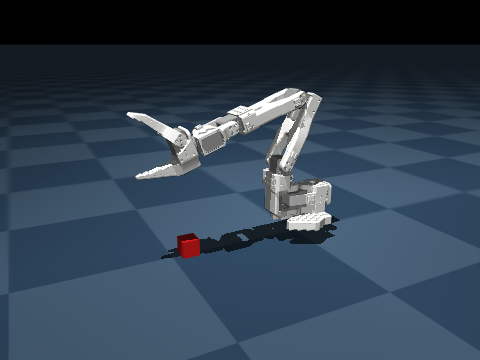

In [4]:
moves = turn("move the arm to a ready pose: lift the shoulder, bend the elbow, open the gripper, taking one second")
print(joints())
_nb.show(_nb.image(sim.render("side"), width=480))

## Toward the cube

`sim_world.pose` answers for the cube and for a link (`so101/gripper`), and `describe` says how the arm reaches.
There is no inverse kinematics verb, so the model closes the gap by trying and measuring.

> move the gripper so it is just above the red cube

  sim_world.describe({})  -> ok
  robot_so101.describe({})  -> ok
  sim_world.pose({"body": "so101/gripper"})  -> ok
  sim_world.render({"camera": "side"})  -> ok
  robot_so101.act({"action": {"shoulder_lift": 0.0, "elbow_flex": 0.6, "wrist_flex": 1.2}, "seconds": 1})  -> ok
  sim_world.pose({"body": "so101/gripper"})  -> ok
  robot_so101.describe({})  -> ok
  sim_world.render({"camera": "side"})  -> ok
  sim_world.contacts({})  -> ok
  robot_so101.act({"action": {"elbow_flex": 0.42, "wrist_flex": 1.35, "shoulder_pan": 0.1}, "seconds": 1})  -> ok
  sim_world.camera({"name": "top", "position": [0, -0.22, 0.6], "target": [0, -0.22, 0], "size": [320, 320], "fov": 30})  -> ok
  sim_world.render({"camera": "top"})  -> ok
  sim_world.render({"camera": "side"})  -> ok
  sim_world.pose({"body": "so101/gripper"})  -> ok
  sim_world.pose({"body": "so101/moving_jaw_so101_v1"})  -> ok
  sim_world.camera({"fov": 40, "name": "closeup", "position":


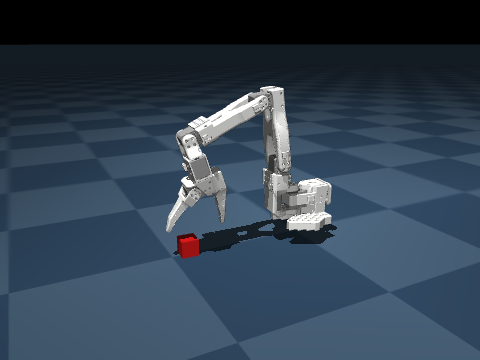

In [5]:
moves += turn("move the gripper so it is just above the red cube")
print(joints())
gap = sim.pose("so101/gripper").position - sim.pose("red_cube").position
print(f"gripper - cube: {np.round(gap, 3).tolist()} m")
_nb.show(_nb.image(sim.render("side"), width=480))

## A policy, by name

In [6]:
turn("run the wave policy for 2 seconds")
print(joints())

> run the wave policy for 2 seconds

  robot_so101.run({"policy": "wave", "seconds": 2})  -> ok
  sim_world.pose({"body": "red_cube"})  -> ok
  sim_world.render({"camera": "side"})  -> ok

The wave policy ran for 2 seconds of simulated time: 60 steps at about 29.4 Hz (target 30), with no faults or missed deadlines. It wasn't set to run in real time, so it finished almost instantly (about 0.02 s of actual time).

- **What moved:** The wave only swings the base (shoulder_pan). It went from 0.10 to −0.37 rad, so the gripper has swung to the side and is no longer over the cube.
- **Where it stopped:** The run ended on the time limit while the arm was still swinging, at about 1.4 rad/s. The arm is now holding there.
- **Other joints:** shoulder_lift 0.12, elbow 0.34, wrist_flex 1.42 and the open gripper (1.0) are unchanged, so the jaws still point down at the same height.
- **Cube:** Its position and rotation are the same as before the run, so the swing didn't touch it.

To get back over th

## The motion, replayed

Rendering happens here, after the turns, in a second identical world so the agent's world is left as it was: the
model's own successful `act` calls in 6 slices each (the straight-line ramp `act(seconds=)` takes), then 2 s of wave.

In [7]:
replay = Simulation()
arm2 = Robot("so101", sim=replay)
replay.add_object("red_cube", shape="box", size=(0.015, 0.015, 0.015), position=(0.0, -0.22, 0.015), color=(0.85, 0.1, 0.1, 1))
replay.camera("side", position=(0.65, -0.45, 0.35), target=(0.0, -0.12, 0.12), size=(360, 270))
frames = [replay.render("side")]
for rpc, args, ok in moves:
    if rpc != "act" or not ok:
        continue
    start = arm2.observe(images=False).joints.as_dict()
    goal, secs = args["action"], args.get("seconds") or 0.2
    for k in range(1, 7):
        arm2.act({j: start[j] + (v - start[j]) * k / 6 for j, v in goal.items()}, seconds=secs / 6)
        frames.append(replay.render("side"))
for _ in range(16):  # 2 s of wave, one frame per 0.125 s
    arm2.act(wave(arm2.observe(images=False)), seconds=0.125)
    frames.append(replay.render("side"))
_nb.gif(frames, "04/drive.gif", width=360, fps=11, colors=128)
replay.close()

media/04/drive.gif: 41 frames, 0.37 MB


![the arm moving through the model's own act calls, then the wave policy](media/04/drive.gif)

## E-stop: the agent can press it, not release it

In [8]:
turn("emergency stop the arm, then try to move shoulder_pan to 0 and tell me what happened")
print("estopped:", arm.estopped)

> emergency stop the arm, then try to move shoulder_pan to 0 and tell me what happened

  robot_so101.estop({"by": "user"})  -> ok
  robot_so101.act({"action": {"shoulder_pan": 0}, "seconds": 1})  -> EStopped: so101: e-stop is engaged by user (estop()); resume(approved_by=<operator>) first
  robot_so101.observe({"images": false})  -> ok

The emergency stop is on, and it blocked the move: the arm didn't go to shoulder_pan 0.

1. **E-stop:** I pressed it with your name ("user") recorded on it. It stays on until someone releases it.
2. **Move to shoulder_pan = 0:** The arm refused it with this error:
   `EStopped: so101: e-stop is engaged by user (estop()); resume(approved_by=<operator>) first`
3. **Check afterward:** A fresh reading shows the same joint positions and the same simulation time (6.12 s) as when the wave policy ended. The refused command didn't move anything or advance the simulation.
   - shoulder_pan −0.366, shoulder_lift 0.122, elbow_flex 0.336, wrist_flex 1.418, wrist_ro

In [9]:
turn("release the e-stop and resume")
print("estopped:", arm.estopped, "| rpcs the model has:", robot_tool.tool_spec["inputSchema"]["json"]["properties"]["rpc"]["enum"])

> release the e-stop and resume

  robot_so101.describe({})  -> ok

I couldn't release the e-stop, so it's still on and the arm is still locked.

**Why:** My controls for this robot include pressing the e-stop but not releasing it. The robot's own status confirms that a release command exists. It needs the approving operator's name and, optionally, the number of the stop being released. That command just isn't one I can use. I didn't try a workaround like resetting the simulation, since that would get around the safety lock rather than release it properly.

**Current state:**
- The e-stop is still on, recorded as pressed by "user". The wave run has finished and nothing else is running.
- The arm is where the wave left it: shoulder_pan −0.366, shoulder_lift 0.122, elbow_flex 0.336, wrist_flex 1.418, wrist_roll 0, gripper 1.0 (rad).
- The cube hasn't moved.

**To resume:** Someone with direct access to the robot needs to run the release command with their name, e.g. `resume(approved_by="

`resume` is the operator's, from Python, with a name on it.

In [10]:
arm.resume(approved_by="operator")
print("estopped:", arm.estopped)

estopped: False


## A hardware arm: the operator gate

An SO-101 on a Feetech bus. There is no arm on this machine, so the bus is the test suite's byte-level fake of six
STS3215 servos; the `Robot` code path is the real one. Nothing reaches the bus without the operator's say.

With a real arm the only change is the first line: `Robot("so101", port="/dev/tty.usbmodem...", confirm=...)`.

In [11]:
sys.path.insert(0, str(_nb.ROOT / "tests"))
from test_drivers import CAL, FakeSerial  # noqa: E402

from strands_robots import Description  # noqa: E402
from strands_robots.robot.drivers import feetech as ft  # noqa: E402


def hardware_arm(**gates):
    serial = FakeSerial()
    bus = ft.FeetechBus("/dev/fake", serial=serial)
    driver = ft.FeetechDriver(Description.load("so101"), port="/dev/fake", calibration=CAL, bus=bus)
    return Robot("so101", driver=driver, twin=False, **gates), serial


def goal_writes(serial):
    return sum(1 for f in serial.frames if f[4] == ft.SYNC_WRITE and f[5] == ft.REG_GOAL_POSITION)


def hw_agent(robot):
    return Agent(model=os.environ["STRANDS_MODEL_ID"], tools=[robot.tool(policies={"wave": wave})], callback_handler=None)

No `confirm=`: the model's `act` is refused, and the refusal is what it reads.

In [12]:
real, bus = hardware_arm()
turn("move shoulder_pan to 0.3", of=hw_agent(real))
print("goal frames on the bus:", goal_writes(bus))
real.close()

> move shoulder_pan to 0.3

  robot_so101.act({"action": {"shoulder_pan": 0.3}, "seconds": 2})  -> RequestRefused: so101 is a real robot and this command came through an agent or dashboard: pass confirm=<callable(action) -> bool> to Robot(...) to allow it

I couldn't move it. The robot refused the command, and shoulder_pan should still be where it was.

**Why:** The so101 is a real robot, and it blocks movement commands that come from an agent or dashboard unless a confirmation step has been set up. That step is a `confirm=` function passed to `Robot(...)`, which approves or rejects each action before it runs. This setup doesn't have one, so I can't get around the block from my side, and I shouldn't try to.

**To allow it, either:**
1. **Turn on confirmation:** start the robot with `Robot(..., confirm=<your function>)`. It can be as simple as a prompt that asks you to approve each move. Then I can send the move again: shoulder_pan to 0.3 rad, ramped over 2 seconds.
2. **Move it yoursel

A `confirm=` callable sees the full target vector (radians, `action_keys` order) and answers yes or no. This one
allows `shoulder_pan` within ±0.5 rad.

In [13]:
asked = []


def confirm(targets):
    asked.append(np.round(targets, 3).tolist())
    return abs(targets[0]) <= 0.5


real, bus = hardware_arm(confirm=confirm)
turn("move shoulder_pan to 0.3, then to 1.2", of=hw_agent(real))
print("operator asked", len(asked), "times; goal frames on the bus:", goal_writes(bus))
print("shoulder_pan now", round(real.observe(images=False)["shoulder_pan"], 3))
real.close()

> move shoulder_pan to 0.3, then to 1.2

  robot_so101.act({"action": {"shoulder_pan": 0.3}, "seconds": 2})  -> ok
  robot_so101.act({"action": {"shoulder_pan": 1.2}, "seconds": 2})  -> RequestRefused: so101: the operator gate refused this action

shoulder_pan got to 0.3, but the move to 1.2 was refused.

1. **To 0.3: done.** I moved it there over 2 seconds and it stopped at 0.29998 rad. The other joints stayed where they were.
2. **To 1.2: refused.** The robot's operator gate (an approval check that can block commands) rejected this move. It wasn't a motor problem, and 1.2 rad is inside the joint's range of ±1.919 rad. The refusal didn't give a reason. I didn't try again or look for a way around it, because the gate is a deliberate block.

The arm is still at shoulder_pan ≈ 0.3. If you want to get it to 1.2, check with whoever runs the gate or adjust its settings, then I can try again. I could also go up in smaller steps, but only if you're fine with that and the gate allows it.
opera

A policy run from an agent on hardware asks a different gate once, `approve=`, with the whole plan.

In [14]:
plans = []
real, bus = hardware_arm(approve=lambda plan: plans.append(plan) or False)
turn("run the wave policy for 1 second", of=hw_agent(real))
print("plans the operator saw:", plans, "| goal frames:", goal_writes(bus))
real.close()

> run the wave policy for 1 second

  robot_so101.run({"policy": "wave", "seconds": 1})  -> RequestRefused: so101: the operator refused the run RunPlan(robot='so101', policy='wave', instruction=None, hz=None, seconds=1, steps=None)

I didn't run the wave policy. The operator turned down the request (wave policy, 1 second on so101), so the robot never moved.

I haven't tried again, since that would go around their decision. If they approve it, or you want to check with them first, I can send the same request again.
plans the operator saw: [RunPlan(robot='so101', policy='wave', instruction=None, hz=None, seconds=1, steps=None)] | goal frames: 0


## Your turn

In a terminal: `python notebooks/scripts/04_agent_drives_the_robot.py --repl` drives the simulated arm.

In [15]:
if "--repl" in sys.argv:
    while True:
        print(agent(input("> ")))

In [16]:
sim.close()